
# Zone-wise Electricity Demand Pattern Clustering

## 1. Introduction

This notebook focuses on identifying electricity demand patterns across three different zones of Tetouan City using unsupervised machine learning techniques.

The analysis uses K-Means and Hierarchical Clustering to identify similar electricity consumption patterns and understand demand variations across different zones and hours.

## 2. Objectives

- Prepare electricity consumption data for clustering.
- Apply K-Means Clustering.
- Apply Hierarchical Clustering.
- Identify different electricity demand patterns.
- Visualize and compare clustering results.
- Save the final clustering results for further analysis.


In [1]:

# ==========================================
# 3. IMPORT LIBRARIES AND LOAD DATASET
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

# Load original electricity dataset
data_path = "../data/Tetuan City power consumption.csv"

df = pd.read_csv(data_path)

# Convert DateTime column
df["DateTime"] = pd.to_datetime(df["DateTime"])

# Sort dataset by date and time
df = df.sort_values("DateTime").reset_index(drop=True)

# Display dataset information
print("DATASET LOADED SUCCESSFULLY!")
print("=" * 50)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five records:")
display(df.head())


DATASET LOADED SUCCESSFULLY!
Dataset shape: (52416, 9)

Column names:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']

Missing values:
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
dtype: int64

First five records:


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [2]:

# ==========================================
# 4. DATA PREPARATION FOR CLUSTERING
# ==========================================

# Clean column names by removing extra spaces
df.columns = (
    df.columns.astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Select electricity consumption columns
zone_columns = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

print("Available zone columns:")
print([col for col in df.columns if "Zone" in col])

# Verify required columns
for col in zone_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

# Extract date and hour
df["Date"] = df["DateTime"].dt.date
df["Hour"] = df["DateTime"].dt.hour

# Calculate hourly average consumption
hourly_data = (
    df.groupby(["Date", "Hour"])[zone_columns]
    .mean()
    .reset_index()
)

# Create daily electricity demand profiles
daily_profiles = hourly_data.pivot(
    index="Date",
    columns="Hour",
    values=zone_columns
)

# Ensure all 24 hours are available
expected_columns = pd.MultiIndex.from_product(
    [zone_columns, range(24)]
)

daily_profiles = daily_profiles.reindex(
    columns=expected_columns
)

# Rename columns
daily_profiles.columns = [
    f"{zone.replace(' ', '_')}_Hour_{hour:02d}"
    for zone, hour in daily_profiles.columns
]

# Reset index
daily_profiles = daily_profiles.reset_index()

# Select clustering features
feature_columns = [
    col for col in daily_profiles.columns
    if col != "Date"
]

X = daily_profiles[feature_columns].copy()

# Handle missing values
X = X.fillna(X.mean())

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# Display results
print("\nDATA PREPARATION COMPLETED!")
print("=" * 50)
print("Daily profiles shape:", daily_profiles.shape)
print("Clustering features shape:", X.shape)
print("Scaled data shape:", scaled_data.shape)
print("Missing values:", X.isnull().sum().sum())

print("\nDaily demand profiles:")
display(daily_profiles.head())

print("\nScaled data preview:")
display(pd.DataFrame(
    scaled_data,
    columns=feature_columns
).head())


Available zone columns:
['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']

DATA PREPARATION COMPLETED!
Daily profiles shape: (364, 73)
Clustering features shape: (364, 72)
Scaled data shape: (364, 72)
Missing values: 0

Daily demand profiles:


,Date,Zone_1_Power_Consumption_Hour_00,Zone_1_Power_Consumption_Hour_01,Zone_1_Power_Consumption_Hour_02,Zone_1_Power_Consumption_Hour_03,Zone_1_Power_Consumption_Hour_04,Zone_1_Power_Consumption_Hour_05,Zone_1_Power_Consumption_Hour_06,Zone_1_Power_Consumption_Hour_07,Zone_1_Power_Consumption_Hour_08,Zone_1_Power_Consumption_Hour_09,Zone_1_Power_Consumption_Hour_10,Zone_1_Power_Consumption_Hour_11,Zone_1_Power_Consumption_Hour_12,Zone_1_Power_Consumption_Hour_13,Zone_1_Power_Consumption_Hour_14,Zone_1_Power_Consumption_Hour_15,Zone_1_Power_Consumption_Hour_16,Zone_1_Power_Consumption_Hour_17,Zone_1_Power_Consumption_Hour_18,Zone_1_Power_Consumption_Hour_19,Zone_1_Power_Consumption_Hour_20,Zone_1_Power_Consumption_Hour_21,Zone_1_Power_Consumption_Hour_22,Zone_1_Power_Consumption_Hour_23,Zone_2_Power_Consumption_Hour_00,Zone_2_Power_Consumption_Hour_01,Zone_2_Power_Consumption_Hour_02,Zone_2_Power_Consumption_Hour_03,Zone_2_Power_Consumption_Hour_04,Zone_2_Power_Consumption_Hour_05,Zone_2_Power_Consumption_Hour_06,Zone_2_Power_Consumption_Hour_07,Zone_2_Power_Consumption_Hour_08,Zone_2_Power_Consumption_Hour_09,Zone_2_Power_Consumption_Hour_10,Zone_2_Power_Consumption_Hour_11,Zone_2_Power_Consumption_Hour_12,Zone_2_Power_Consumption_Hour_13,Zone_2_Power_Consumption_Hour_14,Zone_2_Power_Consumption_Hour_15,Zone_2_Power_Consumption_Hour_16,Zone_2_Power_Consumption_Hour_17,Zone_2_Power_Consumption_Hour_18,Zone_2_Power_Consumption_Hour_19,Zone_2_Power_Consumption_Hour_20,Zone_2_Power_Consumption_Hour_21,Zone_2_Power_Consumption_Hour_22,Zone_2_Power_Consumption_Hour_23,Zone_3_Power_Consumption_Hour_00,Zone_3_Power_Consumption_Hour_01,Zone_3_Power_Consumption_Hour_02,Zone_3_Power_Consumption_Hour_03,Zone_3_Power_Consumption_Hour_04,Zone_3_Power_Consumption_Hour_05,Zone_3_Power_Consumption_Hour_06,Zone_3_Power_Consumption_Hour_07,Zone_3_Power_Consumption_Hour_08,Zone_3_Power_Consumption_Hour_09,Zone_3_Power_Consumption_Hour_10,Zone_3_Power_Consumption_Hour_11,Zone_3_Power_Consumption_Hour_12,Zone_3_Power_Consumption_Hour_13,Zone_3_Power_Consumption_Hour_14,Zone_3_Power_Consumption_Hour_15,Zone_3_Power_Consumption_Hour_16,Zone_3_Power_Consumption_Hour_17,Zone_3_Power_Consumption_Hour_18,Zone_3_Power_Consumption_Hour_19,Zone_3_Power_Consumption_Hour_20,Zone_3_Power_Consumption_Hour_21,Zone_3_Power_Consumption_Hour_22,Zone_3_Power_Consumption_Hour_23
0,2017-01-01,29197.974683,24657.215190,22083.037973,20811.139240,20475.949367,20807.088607,21648.607595,18540.759495,19605.063290,22905.316455,26685.569620,29288.101265,29889.620255,30231.898735,29898.734177,29218.227847,28730.126583,34423.291137,39619.240507,40318.987342,40371.645568,38712.911392,34972.151897,30072.911392,18026.747720,16078.419453,14330.699088,13219.452887,12921.580547,13069.908815,13596.352585,11449.848023,11738.601822,13814.589667,16232.826750,17772.036473,18187.841947,18378.115503,18099.088145,17722.796352,17503.343465,21094.832827,24361.702127,24692.401215,25406.079028,24836.474163,23067.477203,20105.775077,19252.048193,17042.891567,15676.144578,14883.855422,14317.108433,14395.180722,14513.734938,11552.771085,11190.361447,13026.506023,14801.927712,16000.963855,16853.012048,17298.313253,16873.253013,16594.698795,16388.433733,22275.662650,25729.156627,26186.024095,26493.493978,25344.578313,22582.168673,19578.795180
1,2017-01-02,25303.291138,22512.405062,20945.822783,20097.215188,20066.835442,20838.481012,23307.341773,22895.189872,24368.607595,24505.316455,26384.810127,28224.810127,29581.772152,29485.569620,28611.645570,28971.139240,29996.962027,37022.784812,41747.848100,41498.734178,41096.708862,39461.265823,35830.886075,30112.405063,17007.902733,14910.638300,13835.866263,13466.261398,13248.632217,13910.638298,15348.328267,15709.422492,16416.413373,18190.881458,19947.112462,20830.395137,19950.759878,19572.036473,20161.702128,21335.562310,20641.337388,24476.595745,26987.841947,26857.750760,26782.370822,25874.772035,23548.936170,20373.252282,16884.819278,15079.518072,14165.


Scaled data preview:


,Zone_1_Power_Consumption_Hour_00,Zone_1_Power_Consumption_Hour_01,Zone_1_Power_Consumption_Hour_02,Zone_1_Power_Consumption_Hour_03,Zone_1_Power_Consumption_Hour_04,Zone_1_Power_Consumption_Hour_05,Zone_1_Power_Consumption_Hour_06,Zone_1_Power_Consumption_Hour_07,Zone_1_Power_Consumption_Hour_08,Zone_1_Power_Consumption_Hour_09,Zone_1_Power_Consumption_Hour_10,Zone_1_Power_Consumption_Hour_11,Zone_1_Power_Consumption_Hour_12,Zone_1_Power_Consumption_Hour_13,Zone_1_Power_Consumption_Hour_14,Zone_1_Power_Consumption_Hour_15,Zone_1_Power_Consumption_Hour_16,Zone_1_Power_Consumption_Hour_17,Zone_1_Power_Consumption_Hour_18,Zone_1_Power_Consumption_Hour_19,Zone_1_Power_Consumption_Hour_20,Zone_1_Power_Consumption_Hour_21,Zone_1_Power_Consumption_Hour_22,Zone_1_Power_Consumption_Hour_23,Zone_2_Power_Consumption_Hour_00,Zone_2_Power_Consumption_Hour_01,Zone_2_Power_Consumption_Hour_02,Zone_2_Power_Consumption_Hour_03,Zone_2_Power_Consumption_Hour_04,Zone_2_Power_Consumption_Hour_05,Zone_2_Power_Consumption_Hour_06,Zone_2_Power_Consumption_Hour_07,Zone_2_Power_Consumption_Hour_08,Zone_2_Power_Consumption_Hour_09,Zone_2_Power_Consumption_Hour_10,Zone_2_Power_Consumption_Hour_11,Zone_2_Power_Consumption_Hour_12,Zone_2_Power_Consumption_Hour_13,Zone_2_Power_Consumption_Hour_14,Zone_2_Power_Consumption_Hour_15,Zone_2_Power_Consumption_Hour_16,Zone_2_Power_Consumption_Hour_17,Zone_2_Power_Consumption_Hour_18,Zone_2_Power_Consumption_Hour_19,Zone_2_Power_Consumption_Hour_20,Zone_2_Power_Consumption_Hour_21,Zone_2_Power_Consumption_Hour_22,Zone_2_Power_Consumption_Hour_23,Zone_3_Power_Consumption_Hour_00,Zone_3_Power_Consumption_Hour_01,Zone_3_Power_Consumption_Hour_02,Zone_3_Power_Consumption_Hour_03,Zone_3_Power_Consumption_Hour_04,Zone_3_Power_Consumption_Hour_05,Zone_3_Power_Consumption_Hour_06,Zone_3_Power_Consumption_Hour_07,Zone_3_Power_Consumption_Hour_08,Zone_3_Power_Consumption_Hour_09,Zone_3_Power_Consumption_Hour_10,Zone_3_Power_Consumption_Hour_11,Zone_3_Power_Consumption_Hour_12,Zone_3_Power_Consumption_Hour_13,Zone_3_Power_Consumption_Hour_14,Zone_3_Power_Consumption_Hour_15,Zone_3_Power_Consumption_Hour_16,Zone_3_Power_Consumption_Hour_17,Zone_3_Power_Consumption_Hour_18,Zone_3_Power_Consumption_Hour_19,Zone_3_Power_Consumption_Hour_20,Zone_3_Power_Consumption_Hour_21,Zone_3_Power_Consumption_Hour_22,Zone_3_Power_Consumption_Hour_23
0,-0.231191,-0.640623,-0.843323,-1.155975,-1.466475,-1.412567,-0.867257,-2.104994,-2.244593,-2.091127,-1.762060,-1.533855,-1.540983,-1.496279,-1.449254,-1.437931,-1.517973,-0.183572,0.213619,-0.812506,-0.979502,-0.945075,-1.013037,-0.980191,-0.517821,-0.535333,-0.746554,-1.064017,-1.245333,-0.950971,-0.607499,-1.700887,-1.998391,-1.859495,-1.588583,-1.407105,-1.441020,-1.387025,-1.443143,-1.485915,-1.403066,-0.444499,-0.235164,-0.881790,-0.803623,-0.742889,-0.700330,-0.715094,0.099653,0.013429,-0.061694,-0.083169,-0.098608,0.479105,0.914669,-0.033958,-0.387295,-0.312288,-0.221210,-0.180782,-0.147751,-0.107506,-0.144479,-0.146260,-0.168572,0.745970,0.887856,0.172583,0.063889,0.022457,-0.138664,-0.223670
1,-1.114592,-1.113066,-1.071143,-1.338278,-1.610777,-1.395709,0.057861,-0.437710,-0.712361,-1.600543,-1.852175,-1.847524,-1.632867,-1.725096,-1.842377,-1.513626,-1.104871,0.767613,0.801776,-0.425515,-0.773703,-0.743209,-0.800677,-0.971265,-0.834624,-0.905978,-0.900513,-0.971325,-1.094625,-0.531281,0.187754,-0.003862,-0.384167,-0.462738,-0.437017,-0.485698,-0.899246,-1.025482,-0.817306,-0.364162,-0.427078,0.331304,0.335501,-0.251910,-0.405893,-0.420455,-0.548273,-0.633280,-0.296938,-0.352334,-0.367249,-0.338517,-0.297057,0.338451,0.966946,0.352800,-0.201977,-0.201986,-0.103701,-0.083408,0.099106,0.191893,0.112906,-0.161910,-0.176308,0.783354,0.837107,0.068280,-0.052824,-0.026210,-0.100977,-0.167909
2,-1.122171,-1.085629,-0.985939,-1.220622,-1.593275,-1.290213,0.502912,0.063638,-0.462527,-0.420347,-0.412155,-0.419581,-0.314450,-0.456508,-0.682183,-0.495772,-0.422312,1.062566,1.083823,-0.081707,-0.447

## 4. K-Means Clustering

K-Means clustering is applied to identify different electricity demand patterns based on daily consumption profiles. The optimal number of clusters is selected using the Silhouette Score.

Clusters: 2, Silhouette Score: 0.4497
Clusters: 3, Silhouette Score: 0.3978
Clusters: 4, Silhouette Score: 0.4204
Clusters: 5, Silhouette Score: 0.4029
Clusters: 6, Silhouette Score: 0.3777

Optimal number of clusters: 2

Cluster Distribution:
KMeans_Cluster
0     69
1    295
Name: count, dtype: int64


,Date,KMeans_Cluster
0,2017-01-01,1
1,2017-01-02,1
2,2017-01-03,1
3,2017-01-04,1
4,2017-01-05,1


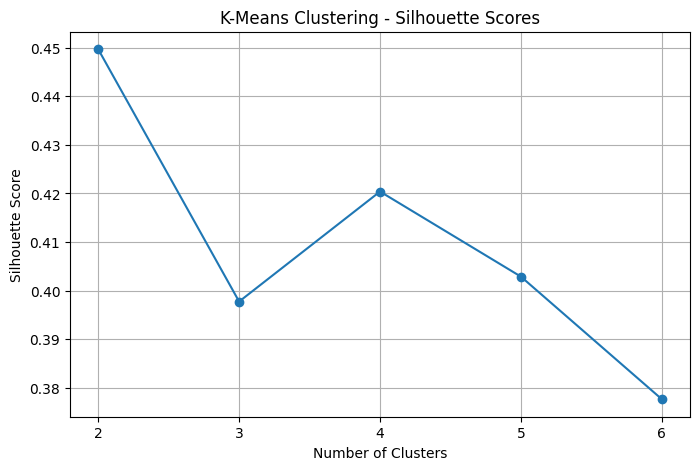

In [3]:

# ==========================================
# 4. K-MEANS CLUSTERING
# ==========================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
silhouette_scores = []

k_values = range(2, 7)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Select optimal number of clusters
best_k = list(k_values)[
    np.argmax(silhouette_scores)
]

print("\nOptimal number of clusters:", best_k)

# Train final K-Means model
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(scaled_data)

# Store clustering results
kmeans_results = daily_profiles[["Date"]].copy()

kmeans_results["KMeans_Cluster"] = kmeans_labels

# Display cluster distribution
print("\nCluster Distribution:")
print(kmeans_results["KMeans_Cluster"].value_counts().sort_index())

display(kmeans_results.head())

# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Clustering - Silhouette Scores")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


## 5. Hierarchical Clustering

Hierarchical clustering is applied to group daily electricity demand profiles based on their similarity. Agglomerative clustering is used to identify demand patterns and compare its results with K-Means clustering.

Clusters: 2, Silhouette Score: 0.4611
Clusters: 3, Silhouette Score: 0.3954
Clusters: 4, Silhouette Score: 0.4185
Clusters: 5, Silhouette Score: 0.3952
Clusters: 6, Silhouette Score: 0.3841

Optimal Hierarchical Clusters: 2

Hierarchical Cluster Distribution:
Hierarchical_Cluster
0    307
1     57
Name: count, dtype: int64


,Date,Hierarchical_Cluster
0,2017-01-01,0
1,2017-01-02,0
2,2017-01-03,0
3,2017-01-04,0
4,2017-01-05,0


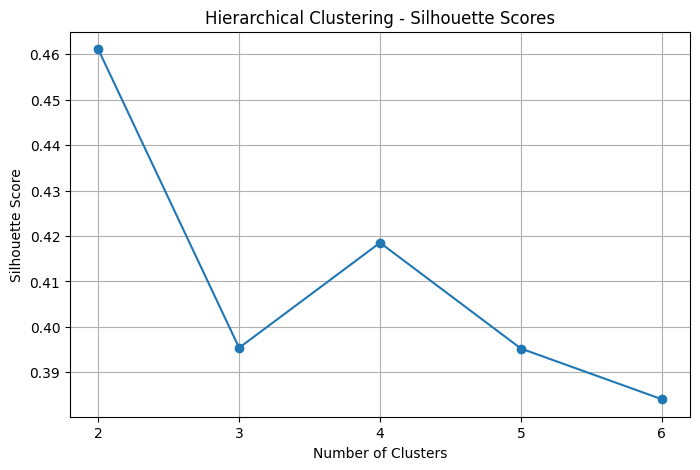

In [4]:

# ==========================================
# 5. HIERARCHICAL CLUSTERING
# ==========================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Test different cluster counts
hierarchical_scores = []
k_values = range(2, 7)

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)

    hierarchical_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Find optimal number of clusters
best_hierarchical_k = list(k_values)[
    np.argmax(hierarchical_scores)
]

print("\nOptimal Hierarchical Clusters:",
      best_hierarchical_k)

# Train final hierarchical model
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_hierarchical_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    scaled_data
)

# Save results
hierarchical_results = daily_profiles[["Date"]].copy()

hierarchical_results["Hierarchical_Cluster"] = (
    hierarchical_labels
)

# Display cluster distribution
print("\nHierarchical Cluster Distribution:")
print(
    hierarchical_results["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

display(hierarchical_results.head())

# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    hierarchical_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering - Silhouette Scores")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


## 6. Cluster Comparison and Visualization

This section compares the clustering results obtained from K-Means and Hierarchical Clustering. PCA is used to reduce the feature dimensions to two components for visualizing the identified electricity demand patterns.

PCA Visualization
Explained variance: 74.86%


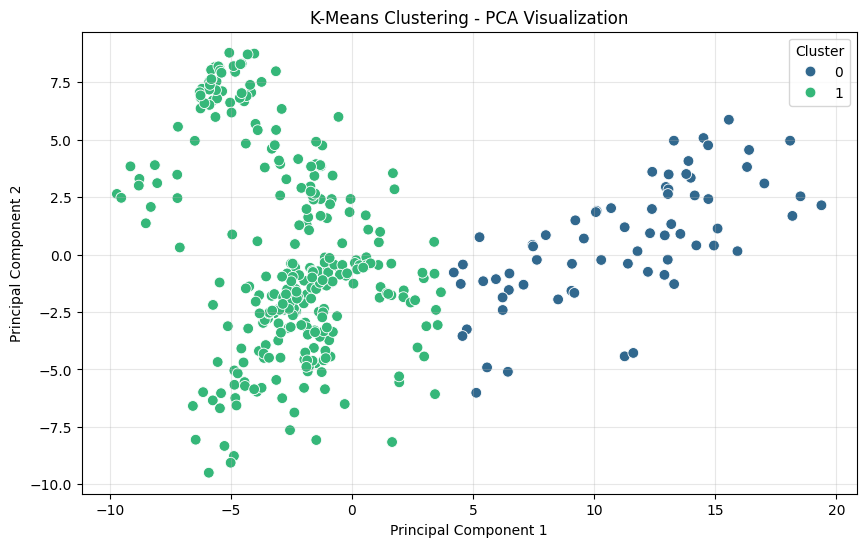

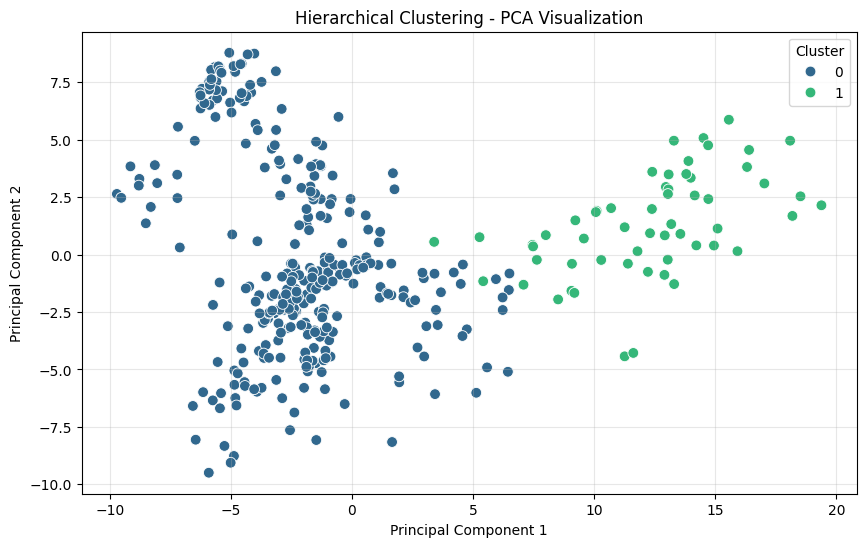


CLUSTERING ALGORITHM COMPARISON


,Algorithm,Optimal_Clusters,Silhouette_Score
0,K-Means,2,0.449660
1,Hierarchical,2,0.461132



Average Demand by Hierarchical Cluster:


,Zone_1_Power_Consumption_Hour_00,Zone_1_Power_Consumption_Hour_01,Zone_1_Power_Consumption_Hour_02,Zone_1_Power_Consumption_Hour_03,Zone_1_Power_Consumption_Hour_04,Zone_1_Power_Consumption_Hour_05,Zone_1_Power_Consumption_Hour_06,Zone_1_Power_Consumption_Hour_07,Zone_1_Power_Consumption_Hour_08,Zone_1_Power_Consumption_Hour_09,Zone_1_Power_Consumption_Hour_10,Zone_1_Power_Consumption_Hour_11,Zone_1_Power_Consumption_Hour_12,Zone_1_Power_Consumption_Hour_13,Zone_1_Power_Consumption_Hour_14,Zone_1_Power_Consumption_Hour_15,Zone_1_Power_Consumption_Hour_16,Zone_1_Power_Consumption_Hour_17,Zone_1_Power_Consumption_Hour_18,Zone_1_Power_Consumption_Hour_19,Zone_1_Power_Consumption_Hour_20,Zone_1_Power_Consumption_Hour_21,Zone_1_Power_Consumption_Hour_22,Zone_1_Power_Consumption_Hour_23,Zone_2_Power_Consumption_Hour_00,Zone_2_Power_Consumption_Hour_01,Zone_2_Power_Consumption_Hour_02,Zone_2_Power_Consumption_Hour_03,Zone_2_Power_Consumption_Hour_04,Zone_2_Power_Consumption_Hour_05,Zone_2_Power_Consumption_Hour_06,Zone_2_Power_Consumption_Hour_07,Zone_2_Power_Consumption_Hour_08,Zone_2_Power_Consumption_Hour_09,Zone_2_Power_Consumption_Hour_10,Zone_2_Power_Consumption_Hour_11,Zone_2_Power_Consumption_Hour_12,Zone_2_Power_Consumption_Hour_13,Zone_2_Power_Consumption_Hour_14,Zone_2_Power_Consumption_Hour_15,Zone_2_Power_Consumption_Hour_16,Zone_2_Power_Consumption_Hour_17,Zone_2_Power_Consumption_Hour_18,Zone_2_Power_Consumption_Hour_19,Zone_2_Power_Consumption_Hour_20,Zone_2_Power_Consumption_Hour_21,Zone_2_Power_Consumption_Hour_22,Zone_2_Power_Consumption_Hour_23,Zone_3_Power_Consumption_Hour_00,Zone_3_Power_Consumption_Hour_01,Zone_3_Power_Consumption_Hour_02,Zone_3_Power_Consumption_Hour_03,Zone_3_Power_Consumption_Hour_04,Zone_3_Power_Consumption_Hour_05,Zone_3_Power_Consumption_Hour_06,Zone_3_Power_Consumption_Hour_07,Zone_3_Power_Consumption_Hour_08,Zone_3_Power_Consumption_Hour_09,Zone_3_Power_Consumption_Hour_10,Zone_3_Power_Consumption_Hour_11,Zone_3_Power_Consumption_Hour_12,Zone_3_Power_Consumption_Hour_13,Zone_3_Power_Consumption_Hour_14,Zone_3_Power_Consumption_Hour_15,Zone_3_Power_Consumption_Hour_16,Zone_3_Power_Consumption_Hour_17,Zone_3_Power_Consumption_Hour_18,Zone_3_Power_Consumption_Hour_19,Zone_3_Power_Consumption_Hour_20,Zone_3_Power_Consumption_Hour_21,Zone_3_Power_Consumption_Hour_22,Zone_3_Power_Consumption_Hour_23
0,29233.802430,26748.904388,25606.574276,24562.579403,23882.819930,23167.903327,22881.775911,23424.568948,25815.897514,28868.704283,31643.126744,33535.087718,34092.730182,34134.791610,33653.860600,32933.994045,32492.667957,34447.322593,39019.538728,42502.151089,42877.874591,41189.959659,37952.453452,33299.919591,18772.861819,16967.813007,16037.673300,15375.664661,15001.289950,14719.734105,14677.387762,15204.314478,16826.091293,18828.495117,20493.460899,21543.790678,22014.849721,22073.24444,21977.898238,21720.294784,21278.709174,22572.953095,25369.984760,27286.752437,27390.942398,26420.628144,24392.326126,21493.437853,16726.538794,15360.891576,14637.963415,13963.284858,13512.239305,12495.481492,11267.991082,10495.324548,11306.959597,12818.927880,14156.090385,15125.408187,15772.704105,16006.946340,15799.014370,15547.862218,15444.252262,17205.057794,20503.346741,23104.178807,23593.313974,22894.586498,21323.277231,18923.762058
1,35513.970689,31963.866241,29988.078298,29515.172646,28677.126427,24890.031702,24936.916610,27344.174617,30716.262727,34339.268153,37539.479051,39617.982550,40221.912818,40376.950284,39974.292513,39179.486542,38192.376753,37497.596207,37912.160366,44378.143583,48910.797718,47745.273226,45080.355081,40386.168881,24642.915682,22059.125337,20459.844112,19698.456033,18978.412233,16349.263872,16320.565769,18491.812979,21319.174217,24015.344328,26005.913129,27283.160211,27519.749335,27726.37377,27581.291201,26753.104489,25977.306247,25507.119048,25842.019166,30077.368942,32473.966036,31581.028311,30092.543244,27561.610446,29055.819181,25641.740271,23215.162096,22107.434555,20912.294

In [5]:

# ==========================================
# 6. CLUSTER COMPARISON AND VISUALIZATION
# ==========================================

from sklearn.decomposition import PCA

# Prepare PCA model
pca = PCA(n_components=2, random_state=42)

pca_data = pca.fit_transform(scaled_data)

# Create visualization dataframe
pca_df = pd.DataFrame({
    "PCA1": pca_data[:, 0],
    "PCA2": pca_data[:, 1],
    "KMeans_Cluster": kmeans_labels,
    "Hierarchical_Cluster": hierarchical_labels
})

# Explained variance
explained_variance = sum(pca.explained_variance_ratio_) * 100

print("PCA Visualization")
print("==============================")
print(f"Explained variance: {explained_variance:.2f}%")

# K-Means visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="viridis",
    s=60
)

plt.title("K-Means Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

# Hierarchical visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Hierarchical_Cluster",
    palette="viridis",
    s=60
)

plt.title("Hierarchical Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

# Compare clustering scores
comparison_df = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Optimal_Clusters": [best_k, best_hierarchical_k],
    "Silhouette_Score": [
        max(silhouette_scores),
        max(hierarchical_scores)
    ]
})

print("\nCLUSTERING ALGORITHM COMPARISON")
display(comparison_df)

# Average demand by hierarchical cluster
cluster_profiles = daily_profiles.drop(
    columns=["Date"]
).groupby(hierarchical_labels).mean()

print("\nAverage Demand by Hierarchical Cluster:")
display(cluster_profiles)



# 7. Save Clustering Results

In this section, the final clustering results are exported
into CSV files for further analysis and reporting.

In [6]:
# ============================================
# 7. SAVE CLUSTERING RESULTS
# ============================================

import os
import pandas as pd

# Create output directory
os.makedirs("../outputs", exist_ok=True)

# Combine clustering results
results_df = pd.DataFrame({
    "Date": daily_profiles["Date"],
    "KMeans_Cluster": kmeans_labels,
    "Hierarchical_Cluster": hierarchical_labels
})

# Save final clustering results
results_df.to_csv(
    "../outputs/clustering_results.csv",
    index=False
)

# Save hierarchical cluster profiles
cluster_profiles.to_csv(
    "../outputs/hierarchical_cluster_profiles.csv"
)

# Save algorithm comparison
comparison_df.to_csv(
    "../outputs/clustering_comparison.csv",
    index=False
)

# Display confirmation
print("======================================")
print("CLUSTERING RESULTS SAVED SUCCESSFULLY!")
print("======================================")

print("\nSaved files:")
print("1. clustering_results.csv")
print("2. hierarchical_cluster_profiles.csv")
print("3. clustering_comparison.csv")

print("\nFinal Results Preview:")
display(results_df.head())

print("\nCluster Distribution:")
print(results_df["Hierarchical_Cluster"].value_counts())

print("\nAll files saved in the outputs folder.")

CLUSTERING RESULTS SAVED SUCCESSFULLY!

Saved files:
1. clustering_results.csv
2. hierarchical_cluster_profiles.csv
3. clustering_comparison.csv

Final Results Preview:


,Date,KMeans_Cluster,Hierarchical_Cluster
0,2017-01-01,1,0
1,2017-01-02,1,0
2,2017-01-03,1,0
3,2017-01-04,1,0
4,2017-01-05,1,0



Cluster Distribution:
Hierarchical_Cluster
0    307
1     57
Name: count, dtype: int64

All files saved in the outputs folder.


# 8. Final Summary and Conclusion

This project successfully applied K-Means and Hierarchical
Clustering to identify daily electricity demand patterns.

Both algorithms identified two optimal clusters.

Hierarchical Clustering achieved a silhouette score of
0.461132, slightly outperforming K-Means with 0.449660.

The analysis identified two distinct electricity demand
profiles across 364 daily observations.

These findings can help understand electricity consumption
patterns and support better energy planning and management.